# LEE classical experiments

This notebook only shows the results. The pseudo-experiments (toys) are generated by the scripts in `../scripts/`, which save their output in `../output/data/` (see the README for the run order); here we load them, print the tables and make the figures, which are written to `../output/plots/classic/`. Common settings and functions are in `../scripts/LEEutils.py`.

In [18]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

sys.path.insert(0, os.path.join("..", "scripts"))
from LEEutils import (BINS, CENTERS, DATA_DIR, DX, FIG_MARGINS, LAM, M_SIG, MU_SIG, N_EVENTS, PLOT_DIR, RANGE,  # noqa: E402
                      SIGMA_SIG, XMAX, XMIN, bkg_pdf, davies_tf, expected_counts, kappa, p_asym, p_gv, p_local,
                      plot_multiple_testing, q_scan, set_style, sig_pdf, sig_shapes, style_legend)

SC_DIR = os.path.join(DATA_DIR, "single_channel")       # run_trials_factor.py, run_grid_scan.py, run_width_scan.py
MC6_DIR = os.path.join(DATA_DIR, "multichannel_6ch")    # run_multichannel_6ch.py
MC50_DIR = os.path.join(DATA_DIR, "screening_50ch")     # run_multichannel_50ch.py
os.makedirs(PLOT_DIR, exist_ok=True)
set_style()

## 1. Classical bump hunt

A simplified bump-hunt: a smooth background with a possible narrow signal on top, as in a search for a new resonance in a mass spectrum.

- **Background:** smoothly falling continuum, truncated exponential on $[x_{\min}, x_{\max}]$:

$$
f_{\text{bkg}}(x \mid \lambda) = \frac{\lambda\, e^{-\lambda x}}{e^{-\lambda x_{\min}} - e^{-\lambda x_{\max}}}
$$

- **Signal:** a resonance at mass $m$ and width $\omega$, truncated Gaussian:

$$
f_{\text{sig}}(x \mid m, \omega) = \frac{\mathcal{N}(x \mid m, \omega)}{\Phi\!\left(\frac{x_{\max}-m}{\omega}\right) - \Phi\!\left(\frac{x_{\min}-m}{\omega}\right)}
$$

- **Mixture model:** signal fraction $\mu$ is the fraction of events from the resonance:

$$
f(x \mid \lambda, m, \mu;\, \omega) = (1-\mu)\,f_{\text{bkg}}(x \mid \lambda) + \mu\,f_{\text{sig}}(x \mid m, \omega)
$$

**From PDF to pseudodata.** Expected count per bin (width $\Delta x$, $N_{\text{tot}}$ total events):

$$
\nu_i \approx N_{\text{tot}}\, f(x_i^{\text{center}})\, \Delta x
$$

Observed counts are a Poisson realization of this expectation, mimicking one run of the experiment:

$$
n_i \sim \text{Poisson}(\nu_i)
$$

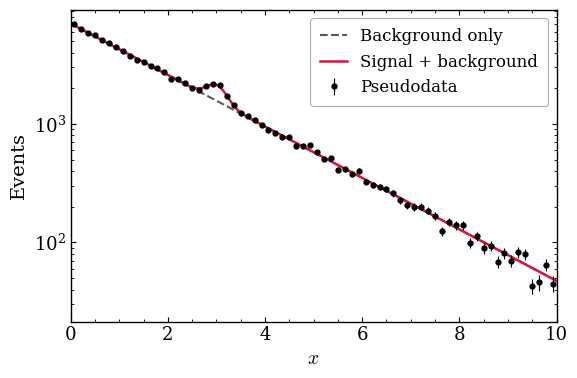

In [19]:
# Poisson fluctuations to simulate observed counts (fixed seed, reproducible)
rng = np.random.default_rng(1234)
exp_counts = expected_counts(LAM, M_SIG, MU_SIG, BINS, N_EVENTS)
data_counts = rng.poisson(exp_counts)
data_err = np.sqrt(data_counts)

# Analytical curves for display (total, background-only)
x_plot = np.linspace(BINS[0], BINS[-1], 500)
pdf_total = (1 - MU_SIG) * bkg_pdf(x_plot, LAM) + MU_SIG * sig_pdf(x_plot, M_SIG)
pdf_bkg = (1 - MU_SIG) * bkg_pdf(x_plot, LAM)

scale = N_EVENTS * DX
pdf_total_scaled = pdf_total * scale
pdf_bkg_scaled = pdf_bkg * scale

# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(CENTERS, data_counts, yerr=data_err, fmt='o', ms=3.5, color='black', ecolor='black', elinewidth=0.8, capsize=0, label='Pseudodata', zorder=5)
ax.plot(x_plot, pdf_bkg_scaled, ls='--', lw=1.5, color='0.35', label='Background only')
ax.plot(x_plot, pdf_total_scaled, ls='-', lw=1.8, color='crimson', label='Signal + background')

ax.set_xlim(XMIN, XMAX)
ax.set_yscale('log')
ax.set_ylim(bottom=max(1, 0.5 * data_counts[data_counts > 0].min()))
ax.set_xlabel(r'$x$')
ax.set_ylabel('Events')
style_legend(ax.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6))
fig.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'pseudo_data.pdf'), dpi=300)
plt.show()

### 1.1 Null distribution of $q$ and $p$: fixed vs. scanned $m$

We compare two nested hypotheses with a binned Poisson likelihood (total number of events fixed to the observed one):

$$
-\ln \mathcal{L}(\boldsymbol{\theta}) = \sum_i \left( \nu_i(\boldsymbol{\theta}) - n_i \ln \nu_i(\boldsymbol{\theta}) \right)
$$

**Test statistic.** Profile likelihood ratio for a positive signal at fixed $m$ (and $\omega$), restricted to excesses:

$$
q(m) =
\begin{cases}
2 \left[ -\ln \mathcal{L}(\hat{\hat{\lambda}}, \mu{=}0) + \ln \mathcal{L}(\hat{\lambda}_m, m, \hat{\mu}_m) \right] & \hat{\mu}_m \geq 0 \\
0 & \hat{\mu}_m < 0
\end{cases}
$$

Since $\hat\mu_m<0$ in half of the background-only toys, Wilks' theorem gives

$$
q(m) \big|_{H_0} \;\sim\; \tfrac12\delta(q) + \tfrac12\chi^2_{1} \;\equiv\; \tfrac12\chi^2_1, \qquad p(m) = \tfrac12 P\!\left(\chi^2_1 > q(m)\right),
$$

calibrated, $P(p\leq\alpha)=\alpha$, for all $\alpha<\tfrac12$.

**Scanning over $m$.** Without knowing where a resonance sits, we keep the largest value over the scan, $q(\hat m) = \max_{m} q(m)$. This is the look-elsewhere effect: $q(\hat m)$ is not $\tfrac12\chi^2_1$-distributed, and its null distribution has no closed form.

Below, in background-only toys: the distributions of $q(m_0)$ at a fixed $m_0=3$ and of $q(\hat m)$ over 350 mass points; the fraction of toys with $p\leq\alpha$ when both are evaluated with the asymptotic tail; and the histogram of these $p$-values. For $q(\hat m)$ this is the local $p$-value $p_\text{local}$, which is strongly biased towards small values. The fixed-mass $p$-value is uniform below $\tfrac12$; the half of the toys with $q(m_0)=0$ have $p=\tfrac12$ exactly (a point mass), so the histogram only shows $p<\tfrac12$, normalised to all the toys.

100000 fixed-mass toys (m0 = 3, fraction with q = 0: 0.501), 300000 scanned toys


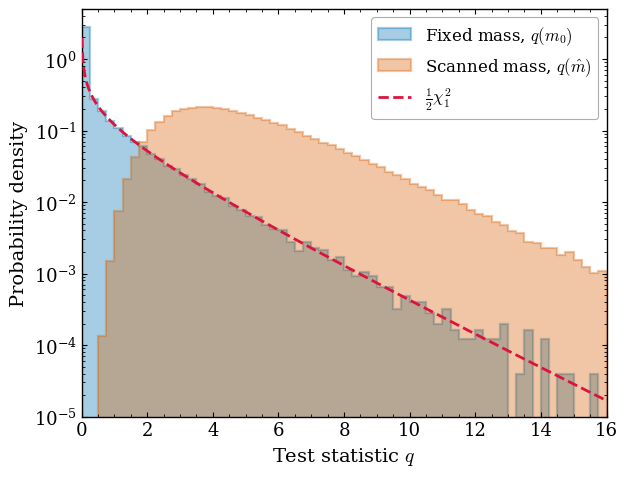

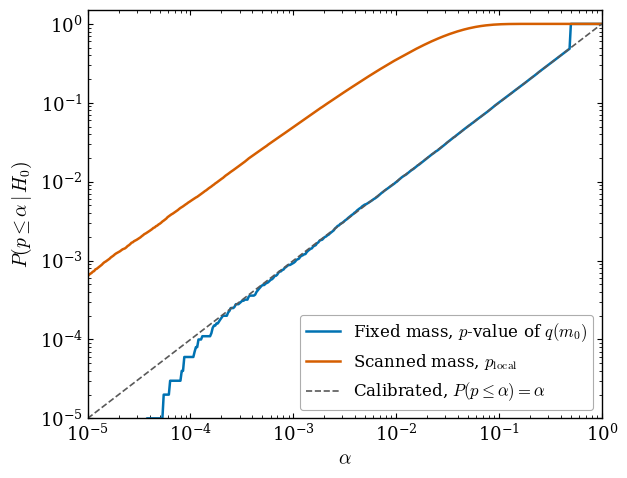

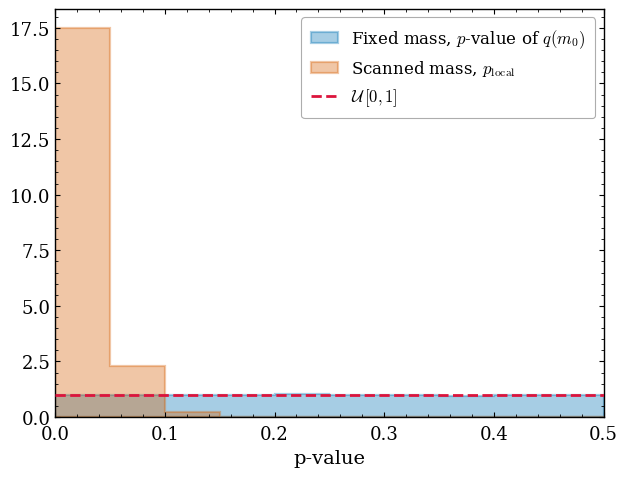

alpha = 0.05: P(p(m0) <= alpha) = 0.0503,  P(p_local <= alpha) = 0.8736
alpha = 0.01: P(p(m0) <= alpha) = 0.0099,  P(p_local <= alpha) = 0.3515
alpha = 0.001: P(p(m0) <= alpha) = 0.0009,  P(p_local <= alpha) = 0.0493


In [20]:
# q(m0): fit at a single, pre-specified mass; q(m_hat): maximum over the 350-point scan (toys of Table 1, Section 1.2)
fixed = np.load(os.path.join(SC_DIR, "q_fixed_m0.npz"))
q0, M0 = fixed["q0"], float(fixed["m0"])
qhat = np.load(os.path.join(SC_DIR, "trials_factor_350.npz"))["qmax"]
print(f"{q0.size} fixed-mass toys (m0 = {M0:g}, fraction with q = 0: {np.mean(q0 == 0):.3f}), {qhat.size} scanned toys")

p0 = p_local(q0)        # valid p-value at a pre-specified mass (p = 1/2 when q = 0)
ploc = p_local(qhat)    # local p-value of the scan maximum

# ----------------------------------------------------------------------
# Plots
# ----------------------------------------------------------------------
# 1) Test statistic distribution under the null hypothesis (background-only)
fig, ax = plt.subplots(figsize=(6.5, 5))
q_bins = np.linspace(0, 16, 65)
ax.hist(q0, bins=q_bins, density=True, histtype='stepfilled', color='#0072B2', alpha=0.35, edgecolor='#0072B2', lw=1.6, label=r'Fixed mass, $q(m_0)$')
ax.hist(qhat, bins=q_bins, density=True, histtype='stepfilled', color='#D55E00', alpha=0.35, edgecolor='#D55E00', lw=1.6, label=r'Scanned mass, $q(\hat m)$')
x_plot = np.linspace(0.01, 16, 500)
ax.plot(x_plot, 0.5 * stats.chi2.pdf(x_plot, 1), '--', color='crimson', lw=2.0, zorder=5, label=r'$\frac{1}{2}\chi^2_1$')
ax.set_yscale('log')
ax.set_xlim(0, 16)
ax.set_ylim(1e-5, 5)
ax.set_xlabel(r'Test statistic $q$')
ax.set_ylabel('Probability density')
style_legend(ax.legend(frameon=True, loc='upper right'))
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, 'q_null_dist.pdf'), dpi=300)

# 2) Calibration of the p-values: fraction of pseudo-experiments with p <= alpha
alpha = np.logspace(-5, 0, 400)
cdf = lambda p: np.searchsorted(np.sort(p), alpha, side='right') / p.size
fig2, ax2 = plt.subplots(figsize=(6.5, 5))
ax2.plot(alpha, cdf(p0), '-', color='#0072B2', lw=1.8, label=r'Fixed mass, $p$-value of $q(m_0)$')
ax2.plot(alpha, cdf(ploc), '-', color='#D55E00', lw=1.8, label=r'Scanned mass, $p_\mathrm{local}$')
ax2.plot(alpha, alpha, '--', color='0.35', lw=1.2, label=r'Calibrated, $P(p\leq\alpha)=\alpha$')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlim(1e-5, 1)
ax2.set_ylim(1e-5, 1.5)
ax2.set_xlabel(r'$\alpha$')
ax2.set_ylabel(r'$P(p\leq\alpha\,|\,H_0)$')
style_legend(ax2.legend(frameon=True, loc='lower right'))
fig2.tight_layout()
fig2.savefig(os.path.join(PLOT_DIR, 'pval_dist.pdf'), dpi=300)

# 3) Distribution of the p-values
fig3, ax3 = plt.subplots(figsize=(6.5, 5))
# Only p < 1/2: the toys with q = 0 have p = 1/2 exactly (point mass). Densities are normalised to all the toys.
p_edges = np.linspace(0, 0.5, 11)
for p_toys, color, label in [(p0, '#0072B2', r'Fixed mass, $p$-value of $q(m_0)$'), (ploc, '#D55E00', r'Scanned mass, $p_\mathrm{local}$')]:
    p_cont = p_toys[p_toys < 0.5]
    ax3.hist(p_cont, bins=p_edges, weights=np.full(p_cont.size, 1 / (p_toys.size * p_edges[1])), histtype='stepfilled', color=color, alpha=0.35, edgecolor=color, lw=1.6, label=label)
# Asymptotic expectation, q ~ 1/2 delta(q) + 1/2 chi2_1: p uniform on (0, 1/2) with density 1
ax3.plot([0, 0.5], [1, 1], '--', lw=2.0, color='crimson', zorder=5, label=r'$\mathcal{U}\,[0,1]$')
ax3.set_xlim(0, 0.5)
ax3.set_ylim(bottom=0)
ax3.set_xlabel(r'p-value')
ax3.tick_params(axis='x', pad=6)
style_legend(ax3.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6))
fig3.tight_layout()
fig3.savefig(os.path.join(PLOT_DIR, 'pval_dist_hist.pdf'), dpi=300)
plt.show()

for a in (0.05, 0.01, 1e-3):
    print(f"alpha = {a:g}: P(p(m0) <= alpha) = {np.mean(p0 <= a):.4f},  P(p_local <= alpha) = {np.mean(ploc <= a):.4f}")

### 1.2 Gross & Vitells correction

Populating the far tail of $q(\hat m)$ with toys is expensive. The **Gross–Vitells** (GV) method instead counts **upcrossings** of a *low* reference level $c_0$ by $q(m)$, averaged over background-only toys, $\langle N(c_0)\rangle$, and extrapolates to the *high* level $c$ of interest:

$$
\langle N(c) \rangle = \langle N(c_0) \rangle \, e^{-(c-c_0)/2}
$$

**Global p-value.** The Davies bound and, with the scaling law, the GV estimate (one-sided, one signal parameter):

$$
p_{\text{global}}(c) \;\leq\; \tfrac{1}{2}P\!\left(\chi^2_1 > c\right) + \langle N(c) \rangle, \qquad\qquad
p_{\text{global}} \;\approx\; p_{\text{local}} + \langle N(c_0)\rangle\, e^{-(c-c_0)/2}
$$

**trial factor** $p_\text{global}/p_\text{local}$ at $c=10$, from the same toys:
- **Davies:** $\langle N(c)\rangle$ counted directly at $c$;
- **GV:** $\langle N(c_0{=}0.5)\rangle$ extrapolated to $c$;
- **Empirical:** fraction of toys with $q(\hat m)\geq c$.

on grids of 100 ($\omega/2$ spacing) and 350 ($\omega/7$) mass points. Davies and empirical refer to the discrete scan, GV to the continuous one (Section 1.3); the Bayer–Seljak row is discussed in Section 1.4.

The figure shows one background-only toy (fixed seed; the first with $3.5<q(\hat m)<5$ at $6<\hat m<9.3$, where the excess is visible on the log scale), its fit, and the upcrossings of $c_0=0.5$ by $q(m)$ and $\sqrt{q(m)}$.

toy 4: m_hat = 7.02, q_hat = 4.47 (Z_local = 2.11), 4 upcrossings of c0 (<N(c0)> = 4.62), p_local = 0.0173, p_global(GV) = 0.65 (Z_global = -0.39)


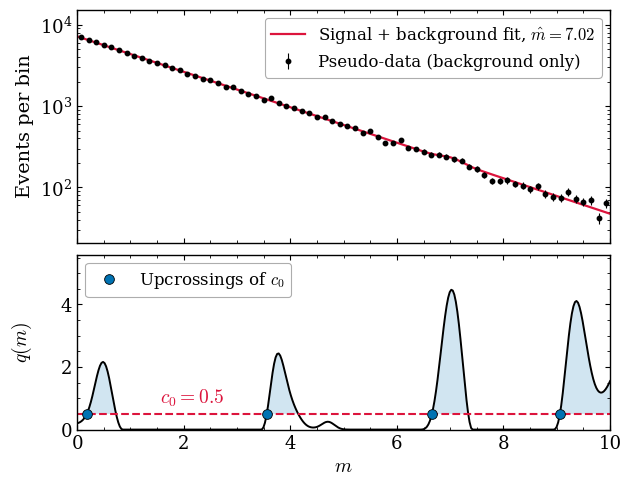

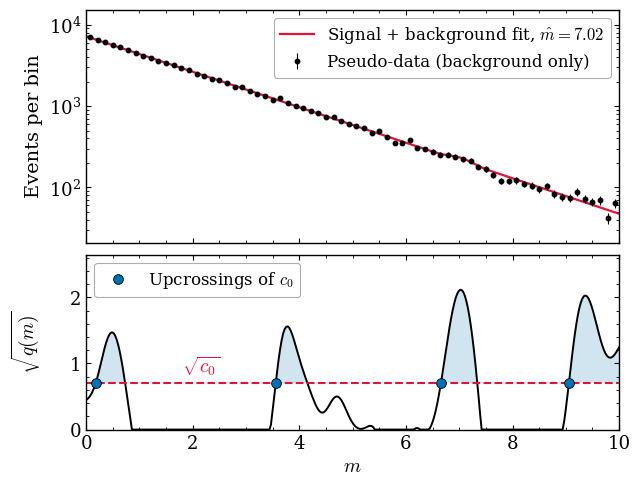

In [21]:
C0 = 0.5     # GV reference level
tf350 = np.load(os.path.join(SC_DIR, "trials_factor_350.npz"))
N0_GV = tf350["up"][:, np.flatnonzero(np.isclose(tf350["levels"], C0))[0]].mean()  # <N(c0)> on the 350-point grid (Table 1 toys)

m_grid = np.linspace(XMIN, XMAX, 350)
mean_bkg = expected_counts(LAM, 1.0, 0.0, BINS, N_EVENTS)
S = sig_shapes(m_grid)

# Fixed seed: first background-only toy with a typical maximum (3.5 < q_hat < 5) in the low-count region 6 < m_hat < 9.3
rng = np.random.default_rng(7)
for itoy in range(1000):
    toy_bkg_data = rng.poisson(mean_bkg).astype(float)
    q_m, mu_m, lam_m, _ = q_scan(toy_bkg_data[None], S)
    q_m, mu_m, lam_m = q_m[0], mu_m[0], lam_m[0]
    j = np.argmax(q_m)
    if 3.5 < q_m[j] < 5 and 6.0 < m_grid[j] < 9.3:
        break
m_hat, q_hat = m_grid[j], q_m[j]
up = np.flatnonzero((q_m[:-1] < C0) & (q_m[1:] >= C0))
m_up = m_grid[up] + (C0 - q_m[up]) / (q_m[up + 1] - q_m[up]) * (m_grid[1] - m_grid[0])   # linear interpolation
p_gv_toy = p_gv(q_hat, N0_GV, C0)
print(f"toy {itoy}: m_hat = {m_hat:.2f}, q_hat = {q_hat:.2f} (Z_local = {np.sqrt(q_hat):.2f}), {len(up)} upcrossings of c0 "
      f"(<N(c0)> = {N0_GV:.2f}), p_local = {p_local(q_hat):.3g}, p_global(GV) = {p_gv_toy:.2f} (Z_global = {stats.norm.isf(p_gv_toy):.2f})")

# Signal + background fit at m_hat
x_plot = np.linspace(XMIN, XMAX, 600)
y_sb = toy_bkg_data.sum() * DX * ((1 - mu_m[j]) * bkg_pdf(x_plot, lam_m[j]) + mu_m[j] * sig_pdf(x_plot, m_hat))

# ----------------------------------------------------------------------
# Plots: q(m) and sqrt(q(m)) versions of the lower panel
# ----------------------------------------------------------------------
for version in ('q', 'sqrtq'):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1.5], "hspace": 0.06})
    ax1.errorbar(CENTERS, toy_bkg_data, yerr=np.sqrt(toy_bkg_data), fmt='o', ms=3.2, color='black', elinewidth=0.8, capsize=0,
                 label='Pseudo-data (background only)', zorder=5)
    ax1.plot(x_plot, y_sb, '-', color='crimson', lw=1.6, label=rf'Signal + background fit, $\hat m={m_hat:.2f}$')
    ax1.set_yscale('log')
    ax1.set_ylabel('Events per bin')
    ax1.set_ylim(0.5 * toy_bkg_data.min(), 2.2 * toy_bkg_data.max())
    style_legend(ax1.legend(frameon=True, loc='upper right'))

    yv = q_m if version == 'q' else np.sqrt(q_m)
    lvl = C0 if version == 'q' else np.sqrt(C0)
    ax2.fill_between(m_grid, lvl, yv, where=yv >= lvl, color='#0072B2', alpha=0.18, lw=0)
    ax2.plot(m_grid, yv, '-', color='black', lw=1.4)
    ax2.axhline(lvl, ls='--', color='crimson', lw=1.5)
    ax2.plot(m_up, np.full(m_up.size, lvl), 'o', color='#0072B2', mec='black', mew=0.6, ms=7, zorder=5, label=r'Upcrossings of $c_0$')
    flat = np.flatnonzero(yv < lvl)                     # put the label where the curve is below c0
    seg = np.split(flat, np.flatnonzero(np.diff(flat) > 1) + 1)
    longest = max(seg, key=len)
    ax2.text(m_grid[longest].mean(), lvl + 0.04 * yv.max(), rf'$c_0={C0:g}$' if version == 'q' else r'$\sqrt{c_0}$',
             color='crimson', va='bottom', ha='center')
    ax2.set_ylim(0, 1.25 * yv.max())
    ax2.set_ylabel(r'$q(m)$' if version == 'q' else r'$\sqrt{q(m)}$')
    ax2.set_xlabel(r'$m$')
    ax2.set_xlim(XMIN, XMAX)
    style_legend(ax2.legend(frameon=True, loc='upper left'))
    fig.align_ylabels([ax1, ax2])
    fig.subplots_adjust(hspace=0.06, **FIG_MARGINS)
    name = 'mu_scan_upcrossings' if version == 'q' else 'mu_scan_upcrossings_sqrtq'
    fig.savefig(os.path.join(PLOT_DIR, f'{name}.pdf'), dpi=300)
plt.show()

In [22]:
# ----------------------------------------------------------------------
# Table 1: trial factor at c = 10 on the 100- and 350-point grids
# ----------------------------------------------------------------------
C = 10.0     # level of interest

def trials_factors(n_grid):
    # Davies, GV, empirical and Bayer-Seljak trial factors at c = C from the toys of one grid
    d = np.load(os.path.join(SC_DIR, f"trials_factor_{n_grid}.npz"))
    qmax, up, lev = d["qmax"], d["up"], d["levels"]
    n = qmax.size
    k_c, k_c0 = np.flatnonzero(np.isclose(lev, C))[0], np.flatnonzero(np.isclose(lev, C0))[0]
    k = np.count_nonzero(qmax >= C)
    f = np.exp(-(C - C0) / 2) / p_local(C)
    r = {"Davies": (1 + up[:, k_c].mean() / p_local(C), up[:, k_c].std() / np.sqrt(n) / p_local(C)),
         "GV": (1 + up[:, k_c0].mean() * f, up[:, k_c0].std() / np.sqrt(n) * f),
         "Empirical": (k / n / p_local(C), np.sqrt(k * (1 - k / n)) / n / p_local(C))}
    # Bayer-Seljak at q = c from peaks near c: N_B scales as sqrt(q), so rescale each toy to q = c
    ok = np.isfinite(d["sig_m"]) & (np.abs(d["q_pk"] - C) < 2)
    kap = d["sig_m"][ok] * np.sqrt(d["q_pk"][ok])
    NB = RANGE * np.sqrt(C) / (np.sqrt(2 * np.pi) * kap)
    tf = (1 - np.exp(-NB * p_asym(C))) / p_local(C)
    r["Bayer-Seljak"] = (tf.mean(), tf.std() / np.sqrt(tf.size))
    extra = dict(n_toys=n, N0=up[:, k_c0].mean(), bs_spread=tf.std(), bs_n=ok.sum(), sqrtlam_curv=1 / kap.mean(),
                 sqrtlam_up=2 * np.pi * up[:, k_c0].mean() * np.exp(C0 / 2) / RANGE, worst_grad=float(d["worst_grad"]))
    return r, extra

tf_table = {g: trials_factors(g) for g in (100, 350)}
print(f"trial factor at c = {C:g} (Z_local = {np.sqrt(C):.2f}), p_local = {p_local(C):.3e}")
print(f"{'Method':14s}{'100 points (sigma/2)':>22s}{'350 points (sigma/7)':>22s}")
for method in ("Davies", "GV", "Empirical", "Bayer-Seljak"):
    print(f"{method:14s}" + "".join(f"{tf_table[g][0][method][0]:14.2f} +- {tf_table[g][0][method][1]:4.2f}" for g in (100, 350)))
for g in (100, 350):
    e = tf_table[g][1]
    print(f"{g}-point grid: {e['n_toys']} toys, <N(c0)> = {e['N0']:.3f}; Bayer-Seljak: spread between toys {e['bs_spread']:.1f} "
          f"({e['bs_n']} toys with |q_hat - c| < 2); worst Newton |grad| = {e['worst_grad']:.1e}")

trial factor at c = 10 (Z_local = 3.16), p_local = 7.827e-04
Method          100 points (sigma/2)  350 points (sigma/7)
Davies                 48.36 +- 0.45         50.81 +- 0.46
GV                     51.56 +- 0.02         52.08 +- 0.02
Empirical              47.76 +- 0.44         50.24 +- 0.45
Bayer-Seljak           51.36 +- 0.06         52.24 +- 0.06
100-point grid: 300000 toys, <N(c0)> = 4.574; Bayer-Seljak: spread between toys 10.3 (27777 toys with |q_hat - c| < 2); worst Newton |grad| = 1.0e-08
350-point grid: 300000 toys, <N(c0)> = 4.621; Bayer-Seljak: spread between toys 10.5 (27984 toys with |q_hat - c| < 2); worst Newton |grad| = 1.1e-05


### 1.3 Gross-Vitells vs Bonferroni correction

We vary only the **density of the mass scan**, $N$, at fixed range:

- **Bonferroni** treats the $N$ points as independent tests: trial factor $=N$, growing without bound even once the spacing is finer than $\omega$.
- **Gross–Vitells** measures the effective number of trials from the upcrossings of $c_0$, a property of the continuous curve $q(m)$:

    $$
    \frac{p_{\text{global}}}{p_{\text{local}}} \approx 1 + 2\cdot\frac{\langle N(c_0) \rangle\, e^{-(c - c_0)/2}}{P(\chi^2_1 > c)}
    $$

    so it **converges** once the grid resolves the correlation length $\sim\omega$.

The trial factor of the **discrete scan**, $P(\max_{i} q(m_i)>c\,|\,H_0)/p_\text{local}$, is what toys on the $N$-point grid measure (open diamonds); it never exceeds $N$. GV estimates its limit for an infinitely dense grid, the **continuous scan**. All curves use the same toys.

- **Coarse grid** (spacing $>$ width of the peaks of $q(m)$): the points are effectively independent and Bonferroni is accurate. GV overshoots, because its extrapolation assumes a smooth process: for independent points a fraction $P(q<c_0)P(q\geq c_0)\approx18\%$ of the steps upcross $c_0=0.5$, which extrapolates to about $1+2N$ at $c=10$. With $c_0=7.5$ the extrapolation is short and GV follows Bonferroni.
- **Dense grid:** every upcrossing is resolved and GV no longer depends on $N$. Higher $c_0$ gives narrower excursions, so it needs a denser grid.

10000 toys, trial factor at c = 10
   N  spacing/sigma     GV c0=0.5       GV c0=7.5     empirical (discrete scan)
  11     5.00        22.6 +-  0.1     12.1 +-  0.6      10.9 +-  1.2
  21     2.50        39.4 +-  0.1     24.0 +-  0.9      20.4 +-  1.6
  31     1.67        46.0 +-  0.1     30.9 +-  1.0      29.5 +-  1.9
  41     1.25        48.7 +-  0.1     37.5 +-  1.1      32.2 +-  2.0
  51     1.00        50.0 +-  0.1     41.7 +-  1.2      39.0 +-  2.2
  61     0.83        50.6 +-  0.1     43.9 +-  1.2      42.2 +-  2.3
  71     0.71        51.1 +-  0.1     45.6 +-  1.2      44.5 +-  2.3
  81     0.62        51.4 +-  0.1     47.1 +-  1.3      43.4 +-  2.3
  91     0.56        51.6 +-  0.1     47.5 +-  1.3      45.9 +-  2.4
 101     0.50        51.7 +-  0.1     48.2 +-  1.3      45.6 +-  2.4
 111     0.45        51.8 +-  0.1     48.8 +-  1.3      47.3 +-  2.4
 121     0.42        51.9 +-  0.1     48.5 +-  1.3      47.5 +-  2.4
 131     0.38        52.0 +-  0.1     49.1 +-  1.3      4

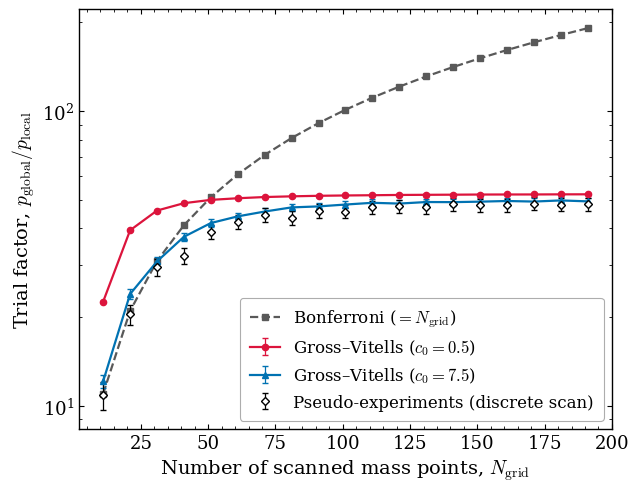

In [23]:
g = np.load(os.path.join(SC_DIR, "grid_scan.npz"))
N_points, C0_LIST, up_grid, qmax_grid = g["n_points"], g["c0"], g["up"], g["qmax"]
n_toys_grid = qmax_grid.shape[0]

trial_gv = {c0: 1 + up_grid[:, :, l].mean(axis=0) * np.exp(-(C - c0) / 2) / p_local(C) for l, c0 in enumerate(C0_LIST)}
trial_gv_std = {c0: up_grid[:, :, l].std(axis=0) / np.sqrt(n_toys_grid) * np.exp(-(C - c0) / 2) / p_local(C) for l, c0 in enumerate(C0_LIST)}
k = np.count_nonzero(qmax_grid >= C, axis=0)
trial_emp = k / n_toys_grid / p_local(C)
trial_emp_std = np.sqrt(k * (1 - k / n_toys_grid)) / n_toys_grid / p_local(C)

print(f"{n_toys_grid} toys, trial factor at c = {C:g}")
print("   N  spacing/sigma     GV c0=0.5       GV c0=7.5     empirical (discrete scan)")
for i, N in enumerate(N_points):
    print(f" {N:3d}    {RANGE / (N - 1) / SIGMA_SIG:5.2f}      " + "   ".join(f"{trial_gv[c0][i]:6.1f} +- {trial_gv_std[c0][i]:4.1f}" for c0 in C0_LIST)
          + f"    {trial_emp[i]:6.1f} +- {trial_emp_std[i]:4.1f}")

# ------------------------------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 5))

ax.plot(N_points, N_points, '--', color='0.35', lw=1.6, marker='s', ms=4, label=r'Bonferroni ($=N_\text{grid}$)')
gv_styles = {0.5: dict(color='crimson', fmt='o-'), 7.5: dict(color='#0072B2', fmt='^-')}
for c0 in C0_LIST:
    st = gv_styles[c0]
    ax.errorbar(N_points, trial_gv[c0], yerr=trial_gv_std[c0], fmt=st['fmt'], ms=4.5, color=st['color'], ecolor=st['color'],
                elinewidth=0.9, capsize=2, lw=1.6, label=rf'Gross–Vitells ($c_0={c0:g}$)')
ax.errorbar(N_points, trial_emp, yerr=trial_emp_std, fmt='D', ms=4, mfc='white', color='k', ecolor='k',
            elinewidth=0.9, capsize=2, label='Pseudo-experiments (discrete scan)')
ax.set_xlabel(r'Number of scanned mass points, $N_\text{grid}$')
ax.set_ylabel(r'Trial factor, $p_{\mathrm{global}}/p_{\mathrm{local}}$')
ax.set_yscale('log')
style_legend(ax.legend(frameon=True, loc='lower right', handlelength=1.8, borderpad=0.6))
fig.subplots_adjust(**FIG_MARGINS)
fig.savefig(os.path.join(PLOT_DIR, 'trial_factor_Gv_Bon.pdf'), dpi=300)
plt.show()

### 1.4 An estimate without pseudo-experiments: Bayer & Seljak

The trial factor can also be obtained without toys, as the ratio of the prior to the posterior volume of the signal location (Bayer & Seljak, 2020). The prior range is $U-L=10$, and the posterior width follows from the curvature of $q(m)$ at its maximum, $-\tfrac12\,q''(\hat m)=1/\sigma_m^2$:

$$
N_B=\frac{U-L}{\sqrt{2\pi}\,\sigma_m},\qquad
p_\text{global}\approx1-\exp\!\Big(-N_B\,\frac{e^{-q(\hat m)/2}}{\sqrt{2\pi\,q(\hat m)}}\Big),
$$

with the local $p$-value in its asymptotic form. $q''(\hat m)$ comes from refitting at $\hat m\pm0.02$, independently of the grid spacing.

Near a high peak, $\sigma_m=1/(Z\sqrt{-\rho_{11}})$, so $N_B$ reproduces the leading Davies term: both estimate the same oscillation rate (compared below, from peak curvature and from upcrossings). But GV and Davies average over many toys, while $N_B$ uses the single observed peak, whose curvature fluctuates.

We apply it to each toy of Table 1 (there: average over toys with $|q(\hat m)-c|<2$, rescaled to $c$; the spread between toys is the uncertainty in a single analysis). Left: trial factor vs $Z_\text{local}=\sqrt{q(\hat m)}$ from toys, GV, and Bayer–Seljak (median and central 68%). Right: per-dataset global $p$-values from Bayer–Seljak and GV vs those from the toys, using the peak with the largest $-2\ln p_\text{global}$ (usually the highest).

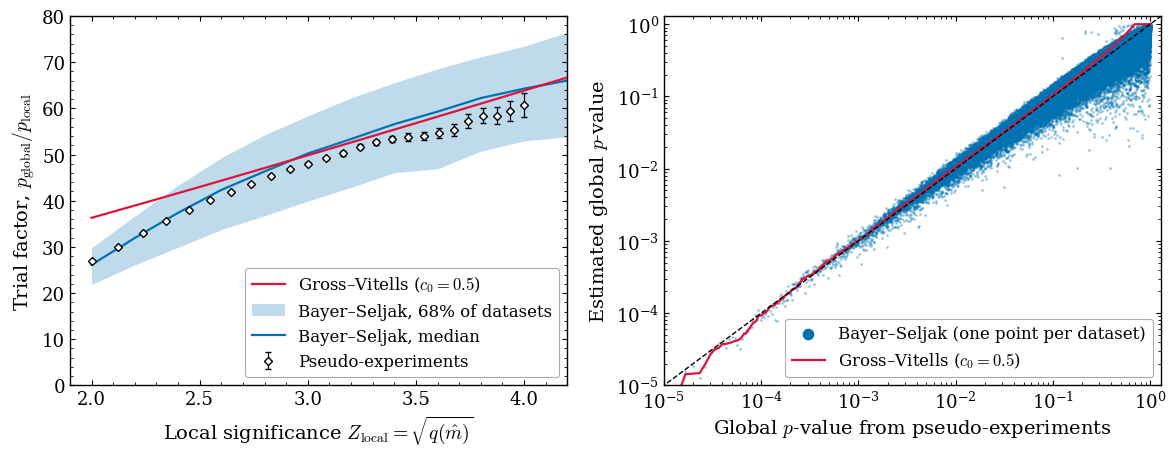

sqrt(-rho_11): from the curvature of the peaks 3.669, from the upcrossings of c0 (GV) 3.728
Bayer-Seljak spread between datasets of the trial factor (std/mean) by Z bin:
  Z = 2.0: 0.16  (1/(sqrt2 Z) = 0.35, 50121 toys)
  Z = 2.5: 0.20  (1/(sqrt2 Z) = 0.28, 33534 toys)
  Z = 3.0: 0.20  (1/(sqrt2 Z) = 0.24, 11925 toys)
  Z = 3.5: 0.19  (1/(sqrt2 Z) = 0.20, 2844 toys)
  Z = 4.0: 0.20  (1/(sqrt2 Z) = 0.18, 469 toys)
Calibration of the Bayer-Seljak global p-value:  alpha, P(p_BS <= alpha)
   0.30  0.3184
   0.10  0.1033
   0.05  0.0507
   0.02  0.0200
   0.01  0.0097
Fraction of highest peaks at the edge of the range: 0.033


In [24]:
d = np.load(os.path.join(SC_DIR, "trials_factor_350.npz"))
e350 = tf_table[350][1]
qmax, lev = d["qmax"], d["levels"]
n = qmax.size

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: trial factor vs local significance
a = ax[0]
cc = np.linspace(4.0, 17.6, 300)
a.plot(np.sqrt(cc), 1 + e350["N0"] * np.exp(-(cc - C0) / 2) / p_local(cc), '-', color='crimson', lw=1.6,
       label=r'Gross–Vitells ($c_0=0.5$)', zorder=3)
kk = np.array([np.count_nonzero(qmax >= c) for c in lev])
sel = (kk >= 30) & (lev >= 4.0)
a.errorbar(np.sqrt(lev[sel]), kk[sel] / n / p_local(lev[sel]), yerr=np.sqrt(kk[sel] * (1 - kk[sel] / n)) / n / p_local(lev[sel]),
           fmt='D', ms=4, mfc='white', color='k', elinewidth=0.9, capsize=2, label='Pseudo-experiments', zorder=4)
ok = np.isfinite(d["sig_m"]) & (d["q_pk"] > 0.5)
qi, si = d["q_pk"][ok], d["sig_m"][ok]
NBi = RANGE / (np.sqrt(2 * np.pi) * si)
tfi = (1 - np.exp(-NBi * p_asym(qi))) / p_local(qi)
zi = np.sqrt(qi)
z_edges = np.arange(1.9, 4.31, 0.2)
zc, med, lo, hi = [], [], [], []
for z0, z1 in zip(z_edges[:-1], z_edges[1:]):
    m = (zi >= z0) & (zi < z1)
    if m.sum() >= 30:
        zc.append(0.5 * (z0 + z1)); med.append(np.median(tfi[m]))
        lo.append(np.percentile(tfi[m], 16)); hi.append(np.percentile(tfi[m], 84))
a.fill_between(zc, lo, hi, color='#0072B2', alpha=0.25, lw=0, label='Bayer–Seljak, 68% of datasets')
a.plot(zc, med, '-', color='#0072B2', lw=1.6, label='Bayer–Seljak, median')
a.set_xlabel(r'Local significance $Z_\mathrm{local}=\sqrt{q(\hat m)}$')
a.set_ylabel(r'Trial factor, $p_{\mathrm{global}}/p_{\mathrm{local}}$')
a.set_xlim(1.9, 4.2)
a.set_ylim(0, 80)
style_legend(a.legend(frameon=True, loc='lower right'))

# Right: per-toy global p-value, Bayer-Seljak and GV vs pseudo-experiments
a = ax[1]
p_emp = 1 - np.searchsorted(np.sort(qmax), qmax, side='left') / n
p_bs = 1 - np.exp(-np.exp(-d["qS_mps"] / 2))
a.scatter(p_emp, p_bs, s=1.5, alpha=0.25, color='#0072B2', rasterized=True, label='Bayer–Seljak (one point per dataset)')
qs = np.sort(qmax)[::-1]
pe = np.arange(1, n + 1) / n
a.plot(pe, p_gv(qs, e350["N0"], C0), '-', color='crimson', lw=1.6, label=r'Gross–Vitells ($c_0=0.5$)')
a.plot([1e-6, 2], [1e-6, 2], 'k--', lw=1)
a.set_xscale('log')
a.set_yscale('log')
a.set_xlim(1e-5, 1.3)
a.set_ylim(1e-5, 1.3)
a.set_xlabel(r'Global $p$-value from pseudo-experiments')
a.set_ylabel(r'Estimated global $p$-value')
leg = style_legend(a.legend(frameon=True, loc='lower right', markerscale=6))
for lh in leg.legend_handles:
    lh.set_alpha(1)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, 'bs_comparison.pdf'), dpi=300)
plt.show()

# Numbers
print(f"sqrt(-rho_11): from the curvature of the peaks {e350['sqrtlam_curv']:.3f}, from the upcrossings of c0 (GV) {e350['sqrtlam_up']:.3f}")
print("Bayer-Seljak spread between datasets of the trial factor (std/mean) by Z bin:")
for z0 in (2.0, 2.5, 3.0, 3.5, 4.0):
    m = (zi >= z0 - 0.1) & (zi < z0 + 0.1)
    if m.sum() > 20:
        print(f"  Z = {z0}: {np.std(tfi[m]) / np.mean(tfi[m]):.2f}  (1/(sqrt2 Z) = {1 / (np.sqrt(2) * z0):.2f}, {m.sum()} toys)")
print("Calibration of the Bayer-Seljak global p-value:  alpha, P(p_BS <= alpha)")
for al in (0.3, 0.1, 0.05, 0.02, 0.01):
    print(f"  {al:5.2f}  {np.mean(p_bs <= al):.4f}")
print(f"Fraction of highest peaks at the edge of the range: {np.mean((d['m_hat'] < 0.06) | (d['m_hat'] > 9.94)):.3f}")

### 1.5 The dependence on the signal template width

$\omega$ sets the correlation length of $q(m)$:

$$
\omega \uparrow \quad\Longrightarrow\quad \langle N(c_0) \rangle \downarrow \quad\Longrightarrow\quad \frac{p_{\text{global}}}{p_{\text{local}}} \downarrow
$$

so the trial factor depends on the signal shape tested, not just on $N$. The background-only toys are the same for every width; only the fit template changes.

**Analytic prediction.** The signed root $Z(m)=\operatorname{sign}(\hat\mu_m)\sqrt{t(m)}$ is asymptotically a unit-variance Gaussian process, and $q(\hat m)>c$ iff $\max_m Z(m)>\sqrt{c}$. The Davies bound then gives $\langle N(c)\rangle=\mathcal{N}e^{-c/2}$ with $\mathcal{N}=\frac{1}{2\pi}\int_L^U\sqrt{-\rho_{11}}\,dm$. For a Gaussian template, ignoring edges and the background fit, $\rho(m',m)=e^{-(m'-m)^2/4\omega^2}$, so

$$
\mathcal{N}=\frac{U-L}{2\sqrt{2}\,\pi\,\omega},\qquad
\frac{p_\text{global}}{p_\text{local}}\approx1+\kappa(c)\,\frac{U-L}{\omega},\qquad
\kappa(c)=\frac{e^{-c/2}}{2\sqrt{2}\,\pi\,\Phi(-\sqrt{c})}
$$

(narrow-template approximation; $\kappa\approx0.93$, $1.2$, $1.5$ at $3$, $4$, $5\,\sigma$).

For broad templates it fails: the background fit absorbs part of the template (more upcrossings) and the templates are truncated at the edges (fewer). Both are included by computing the correlation from the binned templates,

$$
\rho(m',m)=\frac{\langle w_{m'},w_m\rangle}{\lVert w_{m'}\rVert\,\lVert w_m\rVert},\qquad
\langle u,v\rangle=\sum_i\frac{u_i\,v_i}{b_i},
$$

with $w_m$ the template minus its projection onto the directions absorbed by the fit, $b_i$ and $\partial b_i/\partial\nu$ (solid lines; slope fitted or fixed). The sharp drop near $\omega\approx4$ comes from a mass at which the template is almost fully absorbed by the background fit, which leaves the range at $\omega\approx4.2$; fixing the slope (open points) removes it.

1000 toys, 350-point grid, GV with c0 = 0.5, trial factor at c = 10
 sigma   <N(c0)>    TF (slope fitted)   TF (slope fixed)   narrow-template approx.   ratio (fitted)
  0.10    8.892     99.29 +-  0.54     98.53 +-  0.61         97.88             1.01
  0.20    4.625     52.12 +-  0.39     50.43 +-  0.45         49.44             1.05
  0.36    2.715     31.01 +-  0.31     29.19 +-  0.34         28.07             1.10
  0.62    1.762     20.48 +-  0.24     18.23 +-  0.26         16.73             1.22
  0.87    1.290     15.26 +-  0.20     13.26 +-  0.23         12.09             1.26
  1.13    1.063     12.75 +-  0.17     10.94 +-  0.22          9.56             1.33
  1.39    0.855     10.45 +-  0.16      9.31 +-  0.20          7.97             1.31
  1.65    0.736      9.14 +-  0.16      8.05 +-  0.20          6.88             1.33
  1.91    0.639      8.06 +-  0.17      7.18 +-  0.19          6.08             1.33
  2.16    0.596      7.59 +-  0.17      6.21 +-  0.18          5.48

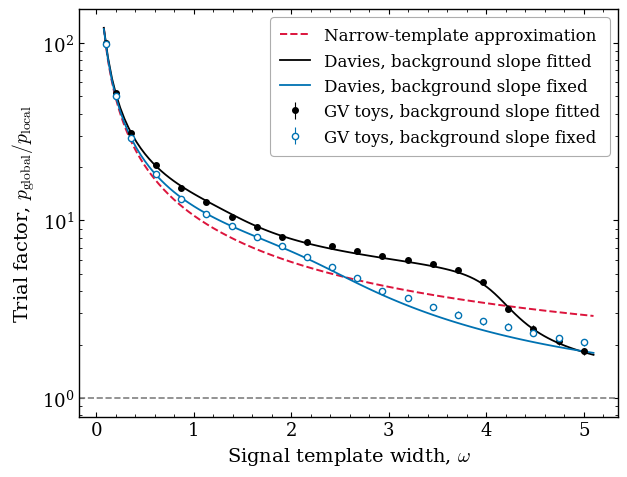

In [25]:
w = np.load(os.path.join(SC_DIR, "width_scan.npz"))
sig_sigma_grid, C0_SIGMA = w["sigmas"], float(w["c0"])
n_toys_sigma = w["up_fit"].shape[0]
extrapol = np.exp(-(C - C0_SIGMA) / 2)
trial_gv_sigma = {k: 1 + w[f"up_{k}"].mean(axis=0) * extrapol / p_local(C) for k in ("fit", "fix")}
trial_gv_sigma_std = {k: w[f"up_{k}"].std(axis=0) / np.sqrt(n_toys_sigma) * extrapol / p_local(C) for k in ("fit", "fix")}
tf_narrow = 1 + kappa(C) * RANGE / sig_sigma_grid

print(f"{n_toys_sigma} toys, {int(w['n_grid'])}-point grid, GV with c0 = {C0_SIGMA:g}, trial factor at c = {C:g}")
print(" sigma   <N(c0)>    TF (slope fitted)   TF (slope fixed)   narrow-template approx.   ratio (fitted)")
for i, s in enumerate(sig_sigma_grid):
    print(f" {s:5.2f}  {w['up_fit'][:, i].mean():7.3f}   {trial_gv_sigma['fit'][i]:7.2f} +- {trial_gv_sigma_std['fit'][i]:5.2f}   "
          f"{trial_gv_sigma['fix'][i]:7.2f} +- {trial_gv_sigma_std['fix'][i]:5.2f}       {tf_narrow[i]:7.2f}            {trial_gv_sigma['fit'][i] / tf_narrow[i]:5.2f}")

# ------------------------------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------------------------------
s_plot = np.linspace(0.08, 5.1, 400)
s_fine = np.linspace(0.08, 5.1, 120)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axhline(1., ls='--', color='gray', lw=1.2)
ax.plot(s_plot, 1 + kappa(C) * RANGE / s_plot, '--', color='crimson', lw=1.4, label='Narrow-template approximation')
ax.plot(s_fine, davies_tf(s_fine, ("norm", "slope"), c=C), '-', color='black', lw=1.3, label='Davies, background slope fitted')
ax.plot(s_fine, davies_tf(s_fine, ("norm",), c=C), '-', color='#0072B2', lw=1.3, label='Davies, background slope fixed')
ax.errorbar(sig_sigma_grid, trial_gv_sigma['fit'], yerr=trial_gv_sigma_std['fit'], fmt='o', ms=4, color='black', ecolor='black',
            elinewidth=0.8, capsize=0, label='GV toys, background slope fitted')
ax.errorbar(sig_sigma_grid, trial_gv_sigma['fix'], yerr=trial_gv_sigma_std['fix'], fmt='o', ms=4.5, mfc='white', color='#0072B2',
            ecolor='#0072B2', elinewidth=0.8, capsize=0, label='GV toys, background slope fixed')
ax.set_xlabel(r'Signal template width, $\omega$')
ax.set_ylabel(r'Trial factor, $p_{\mathrm{global}}/p_{\mathrm{local}}$')
ax.set_yscale('log')
style_legend(ax.legend(frameon=True, loc='upper right', handlelength=1.8, borderpad=0.6))
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, 'tfactor_vs_signalwidth.pdf'), dpi=300)
plt.show()

## 2. Multi-channel search

With several channels (decay modes, event categories), the LEE comes both from the scan within each channel and from the number of channels. Two levels:

- **Within each channel:** the mass scan is corrected with GV ($c_0=0.5$), with $\langle N(c_0)\rangle$ calibrated per channel on its own background and template.
- **Across channels:** Bonferroni ($\alpha/N_\text{ch}$) and Šidák ($1-(1-\alpha)^{1/N_\text{ch}}$, exact for independent channels) control the family-wise error rate (FWER); Benjamini–Hochberg (BH, $k\alpha/N_\text{ch}$ for the $k$-th smallest $p$-value) controls the false discovery rate (FDR). We use $\alpha=0.05$.

Each channel has its own background slope $\nu_i$ and resolution $\omega_i$, used as template width. The resonance is narrow ($\Gamma=0.02$), so its observed width is $\sqrt{\Gamma^2+\omega_i^2}\approx\omega_i$. Signal strengths are set by the expected (Asimov) local significance at the true mass.

The figures show the median GV-corrected $p$-value per channel over the pseudo-experiments (error bars: 16th–84th percentiles), ranked by the median, with the thresholds of each procedure. Since the procedures act on each pseudo-experiment, their error rates are given in the tables: FWER (fraction of experiments selecting at least one background-only channel), FDR (average fraction of background-only channels among those selected), and identification rate of each signal channel.

### 2.1. Particle decay channels

A resonance at $m=3$ decays into $N_\text{ch}=6$ channels with unknown branching ratios and resolutions $\omega_i=0.15$–$0.40$. Signal is injected in channels 1 and 6 (expected $4.5\,\sigma$) and 3 ($3.5\,\sigma$); the other three are background only. The first table gives the channels and the per-channel scans in one pseudo-experiment.

These procedures tell *which* channels contain a signal; a discovery needs a single global $p$-value. A **combined likelihood** with a common mass and a free $\mu_i\geq0$ per channel scans $m$ only once. For independent channels $q_\text{comb}(m)=\sum_i q_i(m)$, whose null distribution at fixed mass is $\sum_{j=0}^{N_\text{ch}}\binom{N_\text{ch}}{j}2^{-N_\text{ch}}\chi^2_j$: it gains from weak excesses at the same mass, but pays for its extra degrees of freedom.

The first figure shows the median over the pseudo-experiments, the second a single pseudo-experiment (that of the table).

In [26]:
calib6 = json.load(open(os.path.join(MC6_DIR, "calib.json")))
single6 = json.load(open(os.path.join(MC6_DIR, "single.json")))

# Table 2: channels and per-channel scan in one pseudo-experiment
print(f"<N(c0)> per channel from {calib6['n_cal']} background-only toys; one pseudo-experiment (seed {single6['seed']}):")
print(" ch    nu  sigma       mu  Z_A      <N(c0)>  m_hat  q(m_hat)   p_local     p_GV  p_GV/p_local")
for r, (N0, N0_err) in zip(single6["channels"], calib6["N0"]):
    print(f"{r['ch']:3d}  {r['nu']:4.2f}  {r['sigma']:5.2f}  {r['mu']:7.4f}  {r['z_asimov']:3.1f}  {N0:5.2f} +- {N0_err:.2f}  {r['m_hat']:5.2f}  "
          f"{r['q_hat']:8.1f}  {r['p_local']:8.2e}  {r['p_gv']:7.2e}  {r['trials']:12.0f}")
print("Selected channels:", single6["selected"])

# Combined fit with a common mass
cb = single6["combined"]
print(f"Combined fit: max_m q_comb(m) = {cb['q']:.1f} at m_hat = {cb['m_hat']:.2f}: local significance {cb['z_local']:.1f} sigma "
      f"(mixture), {cb['z_naive']:.1f} sigma with one degree of freedom; best single channel (ch. {cb['best_ch']}): {cb['z_best_single']:.1f} sigma")

<N(c0)> per channel from 5000 background-only toys; one pseudo-experiment (seed 20261025):
 ch    nu  sigma       mu  Z_A      <N(c0)>  m_hat  q(m_hat)   p_local     p_GV  p_GV/p_local
  1  0.50   0.15   0.0037  4.5   6.05 +- 0.02   3.04      26.4  1.41e-07  1.48e-05           104
  2  0.30   0.25   0.0000  0.0   3.80 +- 0.01   1.63       2.9  4.49e-02  1.00e+00            22
  3  0.40   0.20   0.0035  3.5   4.64 +- 0.02   3.18       5.5  9.39e-03  3.86e-01            41
  4  0.20   0.40   0.0000  0.0   2.48 +- 0.01   0.20       2.6  5.33e-02  9.20e-01            17
  5  0.60   0.30   0.0000  0.0   3.19 +- 0.01   6.91       5.4  1.03e-02  2.90e-01            28
  6  0.35   0.35   0.0062  4.5   2.80 +- 0.01   3.04      38.1  3.33e-10  1.93e-08            58
Selected channels: {'None': [1, 6], 'Bonferroni': [1, 6], 'Sidak': [1, 6], 'BH': [1, 6]}
Combined fit: max_m q_comb(m) = 69.8 at m_hat = 3.04: local significance 7.5 sigma (mixture), 8.4 sigma with one degree of freedom; best single 

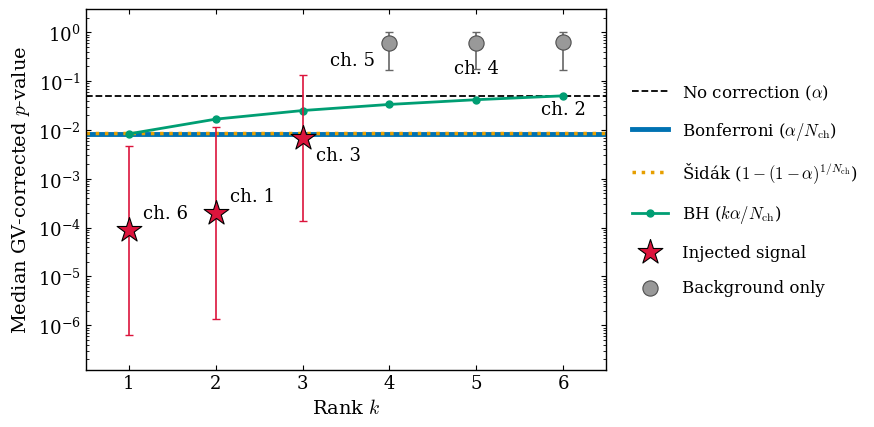

In [27]:
ALPHA = 0.05
ens6 = np.load(os.path.join(MC6_DIR, "ensemble.npz"))
plot_multiple_testing(ens6["p"], ens6["sig_channels"], 'multiple_testing_corrections.pdf', alpha=ALPHA)

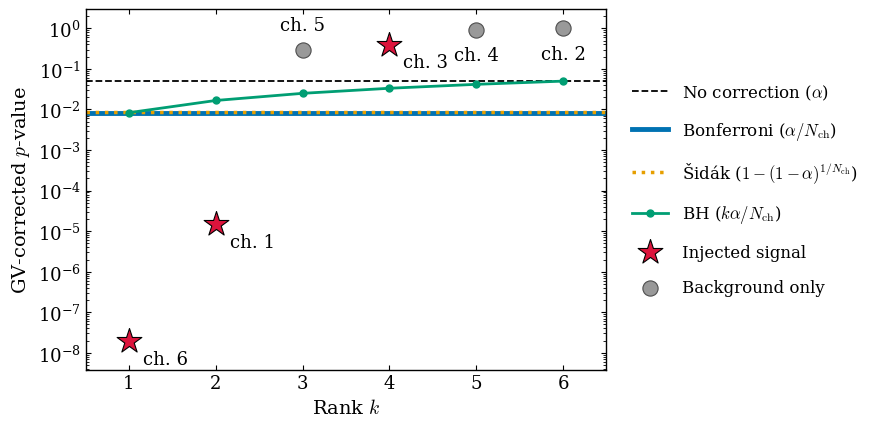

In [28]:
# One pseudo-experiment (a single toy): the one of the first table
sig_channels_6ch = ens6["sig_channels"]
plot_multiple_testing(np.array([r["p_gv"] for r in single6["channels"]]), sig_channels_6ch, 'multiple_testing_corrections_single.pdf', alpha=ALPHA,
                      ylabel='GV-corrected $p$-value')

In [29]:
# Table 3: error rates and identification probabilities over the pseudo-experiments (mean: over the signal channels)
rates6 = json.load(open(os.path.join(MC6_DIR, "ensemble.json")))
sig_names = list(rates6["results"]["None"]["power"])
print(f"{rates6['n_rep']} pseudo-experiments, alpha = {ALPHA}")
print(f"{'Procedure':12s}{'FWER':>15s}{'FDR':>16s}   identification rate: " + "  ".join(f"{s:>5s}" for s in sig_names) + f"  {'mean':>5s}")
for name, r in rates6["results"].items():
    print(f"{name:12s}{r['fwer']:8.3f} +- {r['fwer_err']:.3f}{r['fdr']:9.3f} +- {r['fdr_err']:.3f}{'':23s}"
          + "  ".join(f"{r['power'][s]:5.2f}" for s in sig_names) + f"  {np.mean([r['power'][s] for s in sig_names]):5.2f}")

5000 pseudo-experiments, alpha = 0.05
Procedure              FWER             FDR   identification rate:   ch1    ch3    ch6   mean
None           0.146 +- 0.005    0.043 +- 0.002                        0.92   0.74   0.96   0.87
Bonferroni     0.025 +- 0.002    0.008 +- 0.001                        0.82   0.52   0.88   0.74
Sidak          0.026 +- 0.002    0.009 +- 0.001                        0.82   0.53   0.88   0.74
BH             0.090 +- 0.004    0.026 +- 0.001                        0.88   0.65   0.92   0.82


### 2.2 Unknown physics process

A scaled-down general search: $N_\text{ch}=50$ independent event classes, each with its own background slope ($[0.2,0.6]$) and resolution ($[0.15,0.40]$), fitted as in Section 2.1 with $\langle N(c_0)\rangle$ calibrated per class. A narrow resonance at $m=3$ is injected in 10 random classes, with expected local significances evenly spaced between $2.5\,\sigma$ and $4.5\,\sigma$.

A general search is a screening tool: a false lead only costs a follow-up study, so the natural criterion is the FDR rather than the FWER (which remains the one for a discovery claim). With many classes and several signals, BH and the family-wise procedures differ most. The first figure shows the median over the pseudo-experiments, the second a single pseudo-experiment, in which each procedure selects the classes below its threshold (BH: all classes up to the largest rank below its line). The last figure shows how often each signal class is identified vs its expected significance; a broader template has a smaller trial factor, so it can match a narrower class with slightly higher expected significance.

Signal classes: [3, 10, 16, 19, 22, 24, 29, 32, 46, 47], Z_A = [4.5, 4.28, 2.5, 3.17, 2.72, 3.61, 3.39, 4.06, 2.94, 3.83], sigma = [0.16, 0.218, 0.198, 0.173, 0.183, 0.298, 0.174, 0.385, 0.361, 0.398], mu = [0.00399, 0.00411, 0.00251, 0.00272, 0.00237, 0.00429, 0.00317, 0.00586, 0.00414, 0.00563]
<N(c0)> per class from 2000 background-only toys: from 2.48 to 5.73


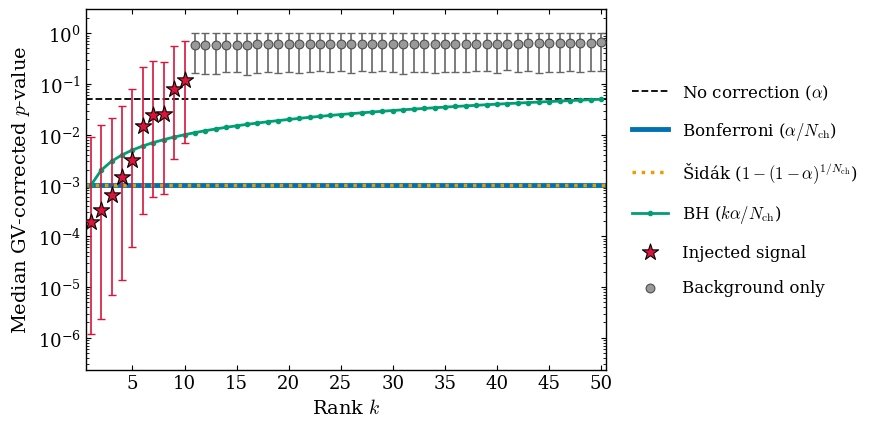

In [30]:
calib50 = json.load(open(os.path.join(MC50_DIR, "calib.json")))
ens50 = np.load(os.path.join(MC50_DIR, "ensemble.npz"))
sig_channels_50ch = ens50["sig_channels"]
N0_50 = np.array([x[0] for x in calib50["N0"]])
print(f"Signal classes: {(sig_channels_50ch + 1).tolist()}, Z_A = {ens50['z_asimov'][sig_channels_50ch].round(2).tolist()}, "
      f"sigma = {ens50['sigma'][sig_channels_50ch].tolist()}, mu = {ens50['mu'][sig_channels_50ch].round(5).tolist()}")
print(f"<N(c0)> per class from {calib50['n_cal']} background-only toys: from {N0_50.min():.2f} to {N0_50.max():.2f}")

plot_multiple_testing(ens50["p"], sig_channels_50ch, 'multiple_testing_corrections_50ch.pdf', alpha=ALPHA)

One pseudo-experiment (seed 20261026), selected classes:
  None         11 (8 with signal): [3, 9, 10, 22, 24, 26, 29, 32, 38, 46, 47]
  Bonferroni    5 (5 with signal): [3, 10, 29, 32, 46]
  Sidak         5 (5 with signal): [3, 10, 29, 32, 46]
  BH            6 (6 with signal): [3, 10, 29, 32, 46, 47]


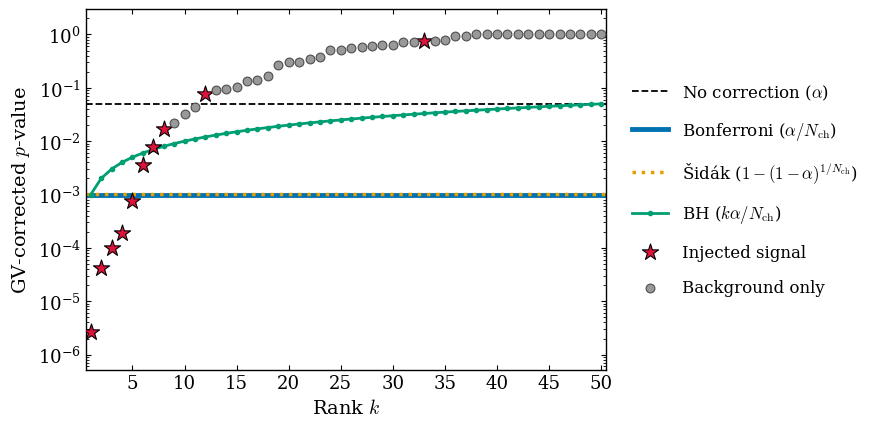

In [31]:
# One pseudo-experiment (a single toy)
single50 = json.load(open(os.path.join(MC50_DIR, "single.json")))
print(f"One pseudo-experiment (seed {single50['seed']}), selected classes:")
for name, sel in single50["selected"].items():
    n_sig = sum(c - 1 in sig_channels_50ch for c in sel)
    print(f"  {name:12s} {len(sel):2d} ({n_sig} with signal): {sel}")

plot_multiple_testing(np.array(single50["p"]), sig_channels_50ch, 'multiple_testing_corrections_50ch_single.pdf', alpha=ALPHA,
                      ylabel='GV-corrected $p$-value')

3000 pseudo-experiments, alpha = 0.05, 10 signal classes out of 50
Procedure              FWER             FDR   identification rate:   ch3   ch10   ch16   ch19   ch22   ch24   ch29   ch32   ch46   ch47   mean
None           0.854 +- 0.006    0.199 +- 0.002                        0.94   0.91   0.36   0.59   0.43   0.79   0.66   0.90   0.59   0.87   0.70
Bonferroni     0.043 +- 0.004    0.011 +- 0.001                        0.66   0.60   0.07   0.20   0.09   0.37   0.25   0.54   0.18   0.46   0.34
Sidak          0.043 +- 0.004    0.011 +- 0.001                        0.66   0.60   0.07   0.20   0.09   0.38   0.25   0.55   0.19   0.47   0.34
BH             0.220 +- 0.008    0.041 +- 0.002                        0.80   0.75   0.15   0.33   0.20   0.56   0.40   0.72   0.32   0.64   0.49


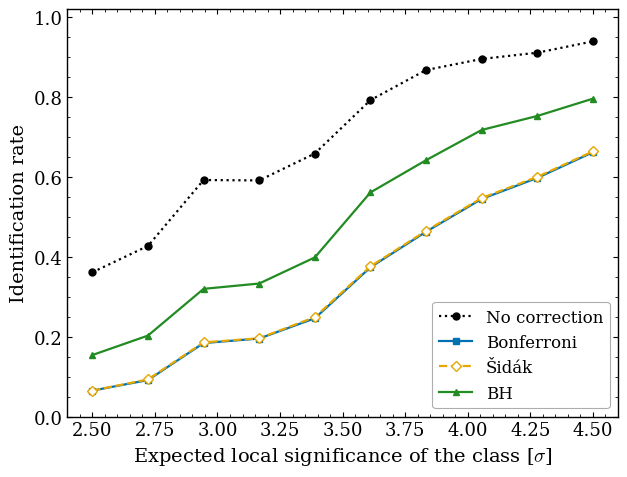

In [32]:
# Table 4: error rates and identification probabilities over the pseudo-experiments (mean: over the signal classes)
rates50 = json.load(open(os.path.join(MC50_DIR, "ensemble.json")))
sig_names50 = list(rates50["results"]["None"]["ident"])
print(f"{rates50['n_rep']} pseudo-experiments, alpha = {ALPHA}, {sig_channels_50ch.size} signal classes out of {ens50['p'].shape[1]}")
print(f"{'Procedure':12s}{'FWER':>15s}{'FDR':>16s}   identification rate: " + "  ".join(f"{'ch' + s:>5s}" for s in sig_names50)
      + f"  {'mean':>5s}")
for name, r in rates50["results"].items():
    print(f"{name:12s}{r['fwer']:8.3f} +- {r['fwer_err']:.3f}{r['fdr']:9.3f} +- {r['fdr_err']:.3f}{'':23s}"
          + "  ".join(f"{r['ident'][s]:5.2f}" for s in sig_names50) + f"  {np.mean([r['ident'][s] for s in sig_names50]):5.2f}")

# ------------------------------------------------------------------------------------------
# Plot: identification rate vs expected significance, over the pseudo-experiments
# ------------------------------------------------------------------------------------------
STYLE = {"None": ("black", ":", "o", "No correction"), "Bonferroni": ("#0072B2", "-", "s", "Bonferroni"),
         "Sidak": ("#e6a800", "--", "D", "Šidák"), "BH": ("forestgreen", "-", "^", "BH")}
z = ens50["z_asimov"][sig_channels_50ch]
o = np.argsort(z)
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (c, ls, mk, lab) in STYLE.items():
    ide = np.array([rates50["results"][name]["ident"][str(int(i) + 1)] for i in sig_channels_50ch])
    ax.plot(z[o], ide[o], ls=ls, marker=mk, color=c, lw=1.6, ms=5, label=lab, mfc='white' if name == 'Sidak' else c)
ax.set_xlabel(r'Expected local significance of the class [$\sigma$]')
ax.set_ylabel('Identification rate')
ax.set_ylim(0, 1.02)
style_legend(ax.legend(frameon=True, loc='lower right'))
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, 'screening_power.pdf'), dpi=300)
plt.show()